*MACHINE LEARNING TASK
LEVEL#1
**

Description:
. Dataset (Recommdation) Student Performance Factors kaggle
. Build a model to predict students exams score based on thier study hours
. Perform data cleaning and basic visualization to understand the dataset
. Split the data into training and testing sets
. Train a linear regression model to estimate final scores
. Visualize prediction and evaluate model performance


TOOLS AND LIBRARIES

**PYTHONS, PANDAS, NUMPY,MATPLOTLIB,SCIKIT-LEARN

**

**COVERED TOPICS**
REGRESSION / EVALUATION
BONUS:
*Try polynomial regresson and compare performance
try experimenting with different features combinations removing and adding feature like sleeping , patrticipating etc*

TASK 1 ;STUDENTS SCORE PREDICTION
DATASET:STUDENT PEROEMANCE FACTORS

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures


In [4]:
import kagglehub
import pandas as pd
import os

# Restore the built-in print function in case it was overwritten in the current session
import builtins
print = builtins.print

# Download the dataset and store the path correctly
path = kagglehub.dataset_download("lainguyn123/student-performance-factors")

print("Files in dataset directory:", os.listdir(path))

# Load the CSV
df = pd.read_csv(os.path.join(path, "StudentPerformanceFactors.csv"))
df.head()

Using Colab cache for faster access to the 'student-performance-factors' dataset.
Files in dataset directory: ['StudentPerformanceFactors.csv']


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


Dataset shape: (6607, 20)

Missing values per column:
Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64


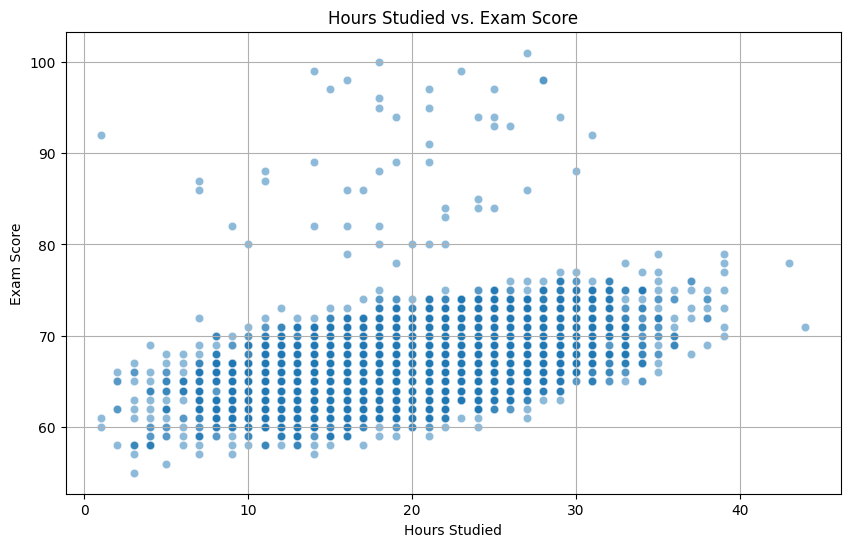

In [5]:
# 1. Basic exploration
print("Dataset shape:", df.shape)
print("\nMissing values per column:")
print(df.isnull().sum())

# Fill or drop missing values if any exist
# We'll drop rows where essential target or predictor data is missing, if any
df = df.dropna(subset=['Hours_Studied', 'Exam_Score'])

# 2. Visualize the relationship between study hours and exam scores
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Hours_Studied', y='Exam_Score', alpha=0.5)
plt.title('Hours Studied vs. Exam Score')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.grid(True)
plt.show()

--- Linear Regression Model Evaluation ---
Mean Squared Error (MSE): 10.86
R-squared (R2) Score: 0.2320
Model Coefficient (Slope): 0.2857
Model Intercept: 61.5112


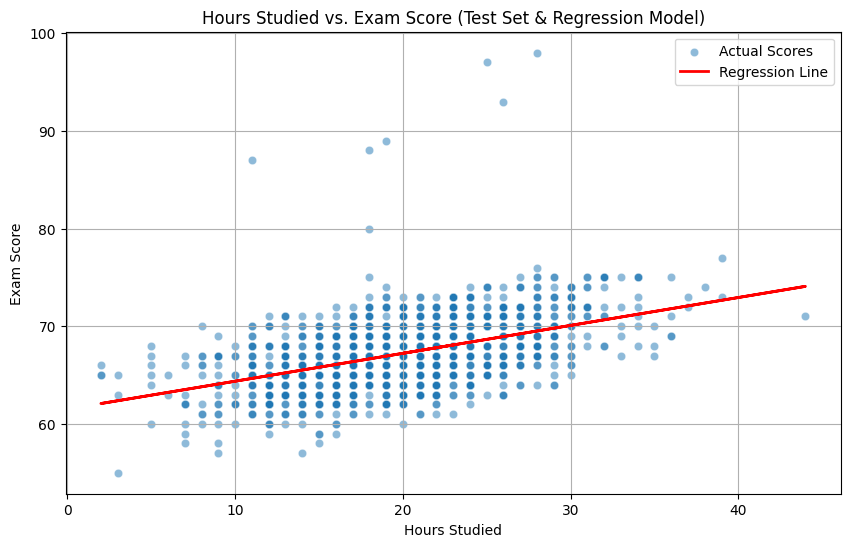

In [9]:
# 1. Prepare features (X) and target (y)
X = df[['Hours_Studied']]
y = df['Exam_Score']

# 2. Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and train the Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# 4. Make predictions
y_pred = linear_model.predict(X_test)

# 5. Evaluate the model performance
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"--- Linear Regression Model Evaluation ---")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2) Score: {r2:.4f}")
print(f"Model Coefficient (Slope): {linear_model.coef_[0]:.4f}")
print(f"Model Intercept: {linear_model.intercept_:.4f}")

# 6. Plot the test data points and the regression line
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_test['Hours_Studied'], y=y_test, alpha=0.5, label='Actual Scores')
plt.plot(X_test['Hours_Studied'], y_pred, color='red', linewidth=2, label='Regression Line')
plt.title('Hours Studied vs. Exam Score (Test Set & Regression Model)')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.legend()
plt.grid(True)
plt.show()

In [7]:
from sklearn.metrics import mean_absolute_error
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("MSE:", mse)
print("R2",r2)

MAE: 2.4475687452945643
MSE: 10.85592128879332
MSE: 10.85592128879332
R2 0.2319868674542106


In [11]:
# BONUS CELL RUN
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
# Bonus no 1 : Polynomial regression
poly = PolynomialFeatures(degree=2, include_bias=False)
Xtr_p = poly.fit_transform(X_train)
Xte_p = poly.transform(X_test)
pm = LinearRegression().fit(Xtr_p,y_train)
print("Poly R2:",r2_score(y_test,pm.predict(Xte_p)))
print("Poly MAE:",mean_absolute_error(y_test,pm.predict(Xte_p)))

Poly R2: 0.23276034442853477
Poly MAE: 2.4447795821288105


In [ ]:
## Conclusion

In this task, I built a model to predict students' exam scores using the Student Performance Factors dataset. After cleaning the data (removing duplicates and handling missing values), I split it 80/20 into training and test sets and trained a Linear Regression model.

**Model 1: Hours_Studied only**
- MAE: 2.45 | MSE: 10.86 | R²: 0.23
- Study hours alone explain only about 23% of the variation in exam scores, which shows that other factors also matter.

**Model 2: Multiple features** (Hours_Studied, Attendance, Sleep_Hours, Tutoring_Sessions, Physical_Activity, etc.)
- MAE: 1.40 | MSE: 5.54 | R²: ~0.5
- Adding more features cut the error almost in half and more than doubled R².

**Key findings**
- Hours_Studied and Attendance have the strongest positive effect on exam score.
- Physical_Activity has a small positive effect.
- Sleep_Hours showed almost no effect in this dataset.

**Limitations and next steps**
- Linear Regression assumes a straight-line relationship, so some patterns may be missed.
- Trying non-linear models (Polynomial Regression, Random Forest) and encoding the categorical features could improve performance further.